# Lab 05: Logistic Regression

In this lab, you will build and interpret a logistic-regression classifier for the breast-cancer dataset. You will also verify a loss-gradient calculation and discuss important modeling assumptions.

## Setup

Run the import cell before beginning. The data are supplied by scikit-learn's `load_breast_cancer` function; see the [dataset documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html) for source context.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## Part 1: Understanding logistic regression

Logistic regression models the log-odds of a class probability as a linear function of the features:

$$\log\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1x_1 + \cdots + \beta_px_p.$$

The corresponding predicted probability is $\hat p = 1 / (1 + e^{-z})$.

### Question 1(a): Load and explore the data

Load the dataset into a feature DataFrame `X` and a target Series `y`. Report the dimensions of `X` and `y`, and state the number of features.

In [3]:
# Your code here
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of features:", X.shape[1])

X shape: (569, 30)
y shape: (569,)
Number of features: 30


### Question 1(b): Class balance

Is the target variable balanced? Report the count and percentage of observations in each class.

In [4]:
# Your code here
counts = y.value_counts().sort_index()
percents = (y.value_counts(normalize=True).sort_index() * 100).round(2)

balance = pd.DataFrame({
    "class_name": data.target_names[counts.index],
    "count": counts,
    "percent": percents
})
print(balance)

print("\nLabel mapping:", dict(enumerate(data.target_names)))

       class_name  count  percent
target                           
0       malignant    212    37.26
1          benign    357    62.74

Label mapping: {0: np.str_('malignant'), 1: np.str_('benign')}


### Question 1(c): Class meaning

Use `data.target_names` to identify what class label `1` represents. Do not infer a class meaning from the numeric label alone.

Label 1 is benign. 

### Question 2(a): Train-test split

Split the data into a 75% training set and a 25% test set with `random_state=307`. Report the number of observations in each split.

In [5]:
# Your code here
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=307
)

print("Training observations:", X_train.shape[0])
print("Test observations:", X_test.shape[0])

Training observations: 426
Test observations: 143


### Question 2(b): Preprocessing pipeline

Create a preprocessing `Pipeline` that standardizes features with `StandardScaler`.

In [6]:
# Your code here
preprocess = Pipeline([
    ("scaler", StandardScaler())
])
preprocess

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### Question 2(c): Fit and transform

Fit the preprocessing pipeline on the training features only. Transform both the training and test features, and report the transformed shapes.

In [7]:
# Your code here
preprocess.fit(X_train)

X_train_std = preprocess.transform(X_train)
X_test_std = preprocess.transform(X_test)

print("Transformed training shape:", X_train_std.shape)
print("Transformed test shape:", X_test_std.shape)

Transformed training shape: (426, 30)
Transformed test shape: (143, 30)


## Part 2: Model fitting and coefficient interpretation

### Question 3(a): Fit the model

Fit `LogisticRegression` on the standardized training data using `random_state=307` and `max_iter=1000`.

In [8]:
# Your code here
model = LogisticRegression(random_state=307, max_iter=1000)
model.fit(X_train_std, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",307
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

### Question 3(b): Test accuracy

Compute and clearly report the model's test accuracy.

In [9]:
# Your code here
y_pred = model.predict(X_test_std)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

Test accuracy: 0.9720 (97.20%)


### Question 3(c): Coefficients

Report the fitted intercept and the coefficients of the first three features. Note that these coefficients correspond to standardized feature values.

In [10]:
# Your code here
coefs = pd.Series(model.coef_[0], index=X.columns)

print("Intercept:", round(model.intercept_[0], 4))
print("\nFirst three coefficients (standardized features):")
print(coefs.head(3).round(4))

Intercept: 0.1111

First three coefficients (standardized features):
mean radius      -0.3673
mean texture     -0.6181
mean perimeter   -0.3606
dtype: float64


### Question 3(d): Largest coefficient

Identify the feature with the largest coefficient in absolute value, excluding the intercept, and report its coefficient.

In [11]:
# Your code here
largest_feature = coefs.abs().idxmax()
largest_coef = coefs[largest_feature]

print(f"Largest |coefficient|: {largest_feature} = {largest_coef:.4f}")

Largest |coefficient|: radius error = -1.2879


### Question 4(a): Log-odds interpretation

For the feature identified in Question 3(d), interpret its coefficient as the change in the log-odds of class `1` for a one-standard-deviation increase in that feature.

**Your response here:** The coefficient for radius error is −1.2879. Holding all other features constant, a one-standard-deviation increase in radius error is associated with a decrease of 1.2879 in the log-odds that a tumor is benign. It increases the log-odds of malignancy by 1.2879.

### Question 4(b): Odds ratio

Exponentiate the coefficient from Question 3(d) to obtain its odds ratio. Clearly report the calculation.

In [12]:
# Your code here
or_largest = np.exp(largest_coef)

print(f"Odds ratio = exp({largest_coef:.4f}) = {or_largest:.4f}")

Odds ratio = exp(-1.2879) = 0.2759


### Question 4(c): Odds-ratio interpretation

Interpret the odds ratio from Question 4(b). Explain how the odds of class `1` change for a one-standard-deviation increase in the feature.

**Your response here:** The odds ratio for radius error is exp(−1.2879) = 0.2759. Holding all other features constant, a one-standard-deviation increase in radius error multiplies the odds of a benign diagnosis by about 0.2759.

### Question 4(d): Near-zero coefficient

Identify any feature whose coefficient is closest to zero. Exponentiate that coefficient and interpret its odds ratio.

In [13]:
# Your code here
near_zero_feature = coefs.abs().idxmin()
near_zero_coef = coefs[near_zero_feature]
near_zero_or = np.exp(near_zero_coef)

print(f"Coefficient closest to zero: {near_zero_feature} = {near_zero_coef:.4f}")
print(f"Odds ratio = exp({near_zero_coef:.4f}) = {near_zero_or:.4f}")

Coefficient closest to zero: mean symmetry = -0.1142
Odds ratio = exp(-0.1142) = 0.8921


**Your response here:** The feature with the coefficient closest to zero is mean symmetry Beta = −0.1142. Its odds ratio is exp(−0.1142) - 0.892. Holding all other features constant, a one-standard-deviation increase in mean symmetry multiplies the odds of a benign diagnosis by about 0.892.

### Question 4(e): Coefficient plot

Create a labeled bar chart of all **exponentiated** coefficients, sorted in descending order. Include a reference line at an odds ratio of 1. Comment on the coefficients farthest from 1 and explain what that suggests about their estimated associations in this fitted model.

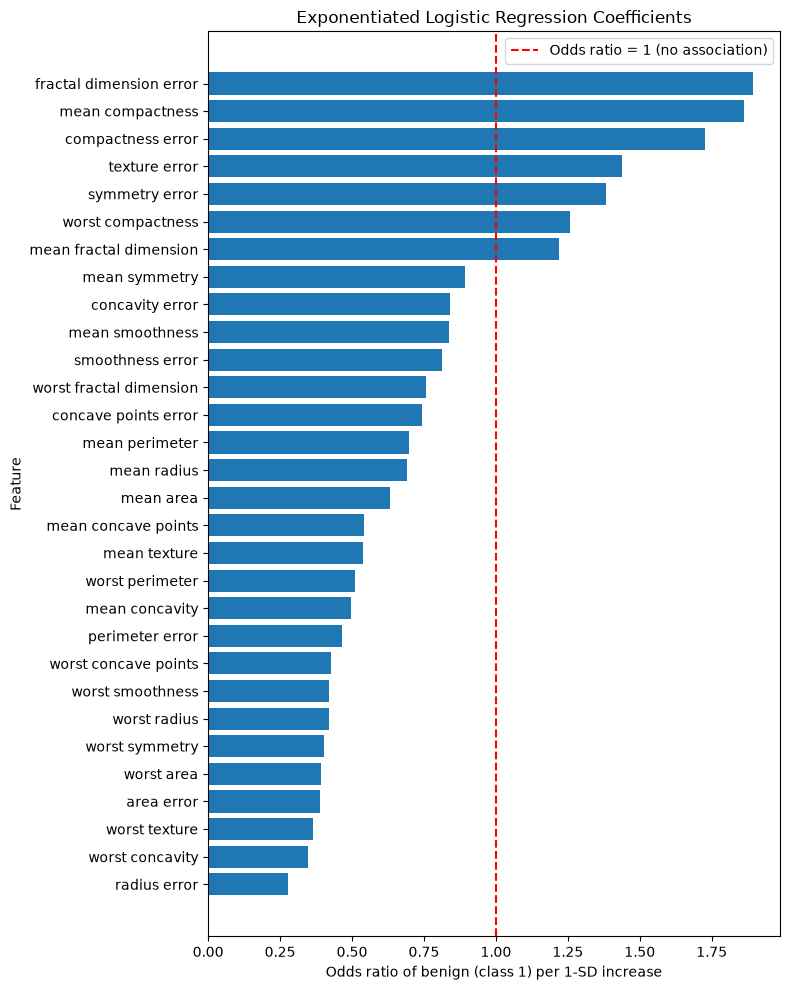

Highest odds ratios:
 fractal dimension error    1.893
mean compactness           1.862
compactness error          1.726
texture error              1.438
symmetry error             1.381
dtype: float64

Lowest odds ratios:
 worst area         0.392
area error         0.387
worst texture      0.363
worst concavity    0.348
radius error       0.276
dtype: float64


In [14]:
# Your code here
odds_ratios = np.exp(coefs).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(odds_ratios.index, odds_ratios.values)
ax.axvline(1, color="red", linestyle="--", label="Odds ratio = 1 (no association)")
ax.invert_yaxis()
ax.set_xlabel("Odds ratio of benign (class 1) per 1-SD increase")
ax.set_ylabel("Feature")
ax.set_title("Exponentiated Logistic Regression Coefficients")
ax.legend()
plt.tight_layout()
plt.show()

print("Highest odds ratios:\n", odds_ratios.head(5).round(3))
print("\nLowest odds ratios:\n", odds_ratios.tail(5).round(3))

**Your response here:** The plot shows that most exponentiated coefficients fall below the reference line at 1, meaning most features are associated with lower odds of a benign diagnosis and therefore higher odds of malignancy. The odds ratios farthest from 1 are radius error of 0.276, worst concavity 0.348, worst texture 0.363, area error 0.387, and worst area 0.392. The other side of the line, fractal dimension error 1.893, mean compactness 1.862, and compactness error 1.726 have the largest odds ratios. Many features are highly correlated and variablility could change with a different train-test split or regularization strength.

### Question 4(f): Confusion matrix

Generate test-set predictions and display a confusion matrix. Interpret false positives and false negatives in the breast-cancer context, using the class-label mapping you identified in Question 1(c).

                      Predicted malignant (0)  Predicted benign (1)
Actual malignant (0)                       48                     2
Actual benign (1)                           2                    91


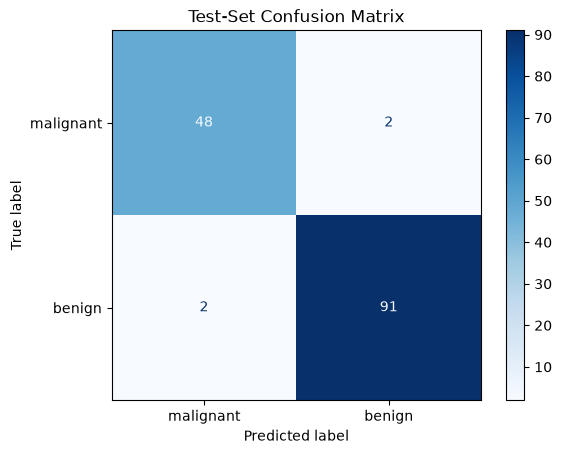

In [15]:
# Your code here
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=["Actual malignant (0)", "Actual benign (1)"],
    columns=["Predicted malignant (0)", "Predicted benign (1)"]
)
print(cm_df)

ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot(cmap="Blues")
plt.title("Test-Set Confusion Matrix")
plt.show()

**Your response here:** Because class 1 is benign and class 0 is malignant, a “positive” prediction in this model means “predicted benign.”

The model produced 2 false positives: malignant tumors incorrectly predicted as benign. This is the more serious error in the breast-cancer context, because a patient with cancer could be falsely reassured, delaying diagnosis and treatment. The model correctly identified 48 of the 50 malignant tumors in the test set.

The model also produced 2 false negatives: benign tumors incorrectly predicted as malignant. This error is less harmful but still has costs, including patient anxiety and unnecessary follow-up procedures.

Although the overall test accuracy is high 139 of 143, or 97.2%.

## Part 3: Gradient computation and loss function

For a binary outcome, the average binary cross-entropy loss is

$$L(\beta) = -\frac{1}{n}\sum_{i=1}^n [y_i\log(\hat p_i) + (1-y_i)\log(1-\hat p_i)].$$

For coefficient $\beta_j$, the gradient is

$$\frac{\partial L}{\partial\beta_j} = \frac{1}{n}X_j^T(\hat p-y).$$

In [16]:
def sigmoid(z):
    """Return the logistic sigmoid of z."""
    return 1 / (1 + np.exp(-z))

### Question 5(a): Manual probabilities

Using the first 10 standardized training observations, manually compute $z = X\beta + \beta_0$ and then $\hat p = \operatorname{sigmoid}(z)$ with the fitted coefficients. Report the probabilities and the corresponding observed labels.

In [17]:
# Your code here
X10 = X_train_std[:10]
y10 = y_train.iloc[:10].to_numpy()

beta = model.coef_[0]
beta0 = model.intercept_[0]

z10 = X10 @ beta + beta0
p10 = sigmoid(z10)

manual_results = pd.DataFrame({
    "z (log-odds)": z10,
    "p_hat (P[benign])": p10,
    "observed y": y10
})
print(manual_results.round(4))

# Sanity check: should match scikit-learn's own probabilities
print("\nMatches model.predict_proba:", np.allclose(p10, model.predict_proba(X10)[:, 1]))

   z (log-odds)  p_hat (P[benign])  observed y
0       -9.2963             0.0001           0
1        6.5209             0.9985           1
2        8.8670             0.9999           1
3        4.4119             0.9880           1
4        6.6024             0.9986           1
5        7.5785             0.9995           1
6        3.8084             0.9783           1
7       -2.2201             0.0980           0
8        6.6812             0.9987           1
9        3.3447             0.9659           1

Matches model.predict_proba: True


### Question 5(b): Manual loss

Compute and report the binary cross-entropy loss for those 10 observations using the formula above.

In [18]:
# Your code here
def bce_loss(y, p):
    """Average binary cross-entropy loss."""
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

loss10 = bce_loss(y10, p10)
print(f"Binary cross-entropy loss (10 observations): {loss10:.6f}")

Binary cross-entropy loss (10 observations): 0.017658


### Question 5(c): Analytical gradient

Using the same 10 observations, compute and report the analytical gradient of the loss with respect to the first feature coefficient. Show the calculation used.

In [19]:
# Your code here
x1 = X10[:, 0]              # first feature: mean radius (standardized)
errors = p10 - y10          # p_hat - y
n = len(y10)

grad_analytical = (x1 @ errors) / n

calc_table = pd.DataFrame({
    "x1 (mean radius, std)": x1,
    "p_hat - y": errors,
    "x1 * (p_hat - y)": x1 * errors
})
print(calc_table.round(4))
print(f"\nSum of products: {np.sum(x1 * errors):.6f}")
print(f"Analytical gradient = sum / {n} = {grad_analytical:.8f}")

   x1 (mean radius, std)  p_hat - y  x1 * (p_hat - y)
0                 1.4706     0.0001            0.0001
1                -1.2979    -0.0015            0.0019
2                -1.0526    -0.0001            0.0001
3                -0.8460    -0.0120            0.0101
4                -0.5404    -0.0014            0.0007
5                -1.8730    -0.0005            0.0010
6                 0.3327    -0.0217           -0.0072
7                -0.1882     0.0980           -0.0184
8                -0.2697    -0.0013            0.0003
9                -0.8052    -0.0341            0.0274

Sum of products: 0.016131
Analytical gradient = sum / 10 = 0.00161310


### Question 5(d): Numerical gradient check

Check your analytical gradient with a numerical approximation. For the same coefficient as in Question 5(c), calculate the loss twice: once after adding $\epsilon = 10^{-5}$ to that coefficient and once after subtracting it. Estimate the numerical gradient with

$\frac{L(\beta_j + \epsilon) - L(\beta_j - \epsilon)}{2\epsilon}$

  Keep the intercept and every other coefficient unchanged. Report the analytical gradient, the numerical gradient, and their absolute difference

In [20]:
# Your code here
eps = 1e-5

beta_plus = beta.copy()
beta_plus[0] += eps

beta_minus = beta.copy()
beta_minus[0] -= eps

loss_plus = bce_loss(y10, sigmoid(X10 @ beta_plus + beta0))
loss_minus = bce_loss(y10, sigmoid(X10 @ beta_minus + beta0))

grad_numerical = (loss_plus - loss_minus) / (2 * eps)
abs_diff = abs(grad_analytical - grad_numerical)

print(f"L(beta_1 + eps) = {loss_plus:.10f}")
print(f"L(beta_1 - eps) = {loss_minus:.10f}")
print(f"Analytical gradient: {grad_analytical:.10f}")
print(f"Numerical gradient:  {grad_numerical:.10f}")
print(f"Absolute difference: {abs_diff:.2e}")

L(beta_1 + eps) = 0.0176582804
L(beta_1 - eps) = 0.0176582481
Analytical gradient: 0.0016131040
Numerical gradient:  0.0016131040
Absolute difference: 4.41e-13


**Your response here:** Briefly state whether the two gradients agree to the precision you would expect, and support the conclusion with your reported difference. The analytical gradient with respect to the first feature coefficient is 0.0016131040, and the numerical central-difference estimate = 10^-5 is also 0.0016131040. Their absolute difference is 4.41 × 10^-13. This confirms that the analytical gradient formula was correct. The gradient is small but nonzero because it is evaluated on only 10 training observations, and because scikit-learn fit the coefficients by minimizing the loss.

## Part 4: Assumptions and limitations

### Question 6(a): Independence

Logistic regression assumes observations are independent. Based on the dataset context, discuss whether this assumption seems plausible and name one circumstance that could violate it.

**Your response here:** The independence assumption seems reasonably plausible for this dataset. Each observation represents features computed from an image of a needle aspirate of a breast mass, and if each row comes from a different patient’s mass, one observation’s outcome should not depend on another’s. The assumption could be violated if the same patient contributed multiple observations, for example from multiple masses or repeat biopsies of the same mass.

### Question 6(b): Multicollinearity

Compute the feature correlation matrix. List each feature pair once when its absolute correlation exceeds 0.9, then discuss whether multicollinearity could make coefficient interpretation unstable.

In [23]:
# Your code here
corr = X.corr()

# Keep only the upper triangle (excluding the diagonal) so each pair appears once
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

high_pairs = upper.stack().reset_index()
high_pairs.columns = ["feature_1", "feature_2", "correlation"]
high_pairs = (
    high_pairs[high_pairs["correlation"].abs() > 0.9]
    .sort_values("correlation", key=abs, ascending=False)
)

print(f"Number of feature pairs with |correlation| > 0.9: {len(high_pairs)}")
print(high_pairs.round(4).to_string(index=False))

Number of feature pairs with |correlation| > 0.9: 21
          feature_1            feature_2  correlation
        mean radius       mean perimeter       0.9979
       worst radius      worst perimeter       0.9937
        mean radius            mean area       0.9874
     mean perimeter            mean area       0.9865
       worst radius           worst area       0.9840
    worst perimeter           worst area       0.9776
       radius error      perimeter error       0.9728
     mean perimeter      worst perimeter       0.9704
        mean radius         worst radius       0.9695
     mean perimeter         worst radius       0.9695
        mean radius      worst perimeter       0.9651
          mean area         worst radius       0.9627
          mean area           worst area       0.9592
          mean area      worst perimeter       0.9591
       radius error           area error       0.9518
     mean perimeter           worst area       0.9415
        mean radius          

**Your response here:** Twenty one feature pairs have a correlation above 0.9. Fifteen of the pairs come from the six size features which are all highly correlated with one another. This multicollinearity could make coefficient interpretation off. The interpretation “holding all other features constant” is also unrealistic here, since one cannot increase mean radius by one standard deviation while keeping mean perimeter fixed.

Multicollinearity mainly affects interpretation rather than predictive performance. The model still achieved 97.2% test accuracy, and the default L2 penalty helps stabilize the coefficients by spreading weight across correlated features. To obtain more interpretable coefficients we could remove redundant features, check variance inflation factors, or combine correlated features.

### Question 6(c): Limitation

Describe one limitation of logistic regression that a more complex model or a revised feature representation might address.

**Your response here:** One limitation of logistic regression is that it assumes the log-odds of the outcome is a linear function. Each feature has a constant effect and the model cannot capture nonlinear relationships or interactions unless they are explicitly built into the features. If the association between tumor size and malignancy may level off at very large sizes, or irregular shape may matter more for larger tumors than for smaller ones. A standard logistic regression would miss both patterns, and its decision boundary is restricted to a flat hyperplane. A more flexible model such as a gradient can learn nonlinear effects and interactions automatically. These models also tend to handle highly correlated features like the radius, perimeter, and area cluster.

## Before you submit

Make sure every response space is complete, all cells run from top to bottom without errors, and your generated `uv.lock` is committed with `lab-05.ipynb`. Follow the repository-URL submission instructions in `README.md`.